<!-- d2l:prose id=kaggle-house-price-md-1 fw=all -->

# Predicting House Prices on Kaggle

Clean image benchmarks like Fashion-MNIST arrive with uniform pixel grids in $[0, 1]$ and zero missing values. Real-world tabular data rarely looks so tidy. In this capstone section of the chapter, we tackle the Kaggle [House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) competition compiled by @De-Cock.2011 from Ames, Iowa property sales (2006–2010): $1{,}460$ labeled training homes and $1{,}459$ unlabeled test homes, each described by $79$ heterogeneous numerical and categorical attributes with scales spanning five orders of magnitude and missing entries across $19$ columns.

Working through this end-to-end tabular pipeline brings together the tools of that section through that section: `pandas` preprocessing without data leakage, logarithmic target transformation, $K$-fold cross-validation on shared folds, linear regression baselines, and He-initialized MLPs regularized with weight decay.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import pandas as pd

<!-- d2l:prose id=kaggle-house-price-md-2 fw=all -->

## The Dataset and the Log-RMSE Metric

We download and cache the training and test CSV files via `d2l.download` and load them into `pandas` DataFrames (that section):

In [3]:
def read_house_prices(root='../data'):
    """Download and read the training and test tables of the competition."""
    train = pd.read_csv(d2l.download(
        d2l.DATA_URL + 'kaggle_house_pred_train.csv', root,
        sha1_hash='585e9cc93e70b39160e7921475f9bcd7d31219ce'))
    test = pd.read_csv(d2l.download(
        d2l.DATA_URL + 'kaggle_house_pred_test.csv', root,
        sha1_hash='fa19780a7b011d9b009e8bff8e99922a8ee2eb90'))
    return train, test

<!-- d2l:prose id=kaggle-house-price-md-3 fw=all -->

Calling `read_house_prices()` loads the two tables into `raw_train` and `raw_test`, whose shapes confirm $1{,}460$ training homes across $81$ columns (including `SalePrice`) and $1{,}459$ test homes across $80$ columns:

In [4]:
raw_train, raw_test = read_house_prices()
print(raw_train.shape, raw_test.shape)

(1460, 81) (1459, 80)


<!-- d2l:prose id=kaggle-house-price-md-4 fw=all -->

Inspecting the first four rows across a few leading and trailing columns of `raw_train` shows a representative mix of integer codes (`Id`, `MSSubClass`), string categories (`MSZoning`, `SaleType`, `SaleCondition`), continuous measurements (`LotFrontage`), and the dollar target `SalePrice`:

In [5]:
print(raw_train.iloc[:4, [0, 1, 2, 3, -3, -2, -1]])

   Id  MSSubClass MSZoning  LotFrontage SaleType SaleCondition  SalePrice
0   1          60       RL         65.0       WD        Normal     208500
1   2          20       RL         80.0       WD        Normal     181500
2   3          60       RL         68.0       WD        Normal     223500
3   4          70       RL         60.0       WD       Abnorml     140000


<!-- d2l:prose id=kaggle-house-price-md-5 fw=all -->

Of the $79$ predictive attributes (after dropping the non-informative row index `Id`), $36$ are stored as numbers and $43$ as strings, with missing values often encoding the absence of a feature (such as `PoolQC = NaN` for homes without a swimming pool).

Because home prices range from $\$34{,}900$ to $\$755{,}000$, a $\$50{,}000$ error is catastrophic on a starter home yet modest on a mansion. Kaggle therefore scores predictions by *relative* accuracy via the root-mean-squared error of the *logarithms* of the prices:

$$\textrm{log-RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n\left(\log y_i - \log \hat{y}_i\right)^2}.$$

For small $\delta = |\log \hat{y} - \log y|$, $\hat{y}/y = e^{\pm \delta} \approx 1 \pm \delta$, so a log-RMSE of $0.135$ corresponds to roughly a $13.5\%$ typical percentage error. By training our models to predict $\log y$ under squared error loss, we optimize the square of the competition metric directly.

## Leakage-Free Preprocessing

Turning the raw DataFrames into float32 feature matrices requires four careful steps, implemented in `preprocess(train, *others)` below:

1. **Recast numeric category codes to strings:** `MSSubClass` uses numbers ($20, 60, 90, \ldots$) to name dwelling styles (1-story, 2-story, duplex); converting it to `str` prevents the model from treating code $90$ as a linear multiple of code $20$.
2. **Standardize numerical features using *training-set* statistics only:** Computing means $\mu$ and standard deviations $s$ exclusively on `train` and applying $(x - \mu)/s$ to both training and validation/test tables puts all numerical features on a unit scale for SGD and weight decay while preventing *data leakage* from validation or test rows.
3. **Impute missing numerical values with $0$ (the training mean):** Filling standardized `NaN` entries with `0` replaces missing numerical measurements by their training-set mean (Exercise 1).
4. **One-hot encode categoricals (`pd.get_dummies(..., dummy_na=True)`):** Expands each categorical column into binary indicators (including an explicit indicator for `NaN`) and aligns validation/test columns to the exact training column vocabulary via `reindex(..., fill_value=0)`:

In [6]:
def preprocess(train, *others):
    """Fit the feature preprocessing on train; apply it to all tables."""
    frames = [df.drop(columns=['Id', 'SalePrice'], errors='ignore')
                .astype({'MSSubClass': str})  # A code, not a quantity
              for df in (train, *others)]
    numeric = frames[0].select_dtypes(include='number').columns
    mean, std = frames[0][numeric].mean(), frames[0][numeric].std()
    for df in frames:
        df[numeric] = ((df[numeric] - mean) / std).fillna(0)
    frames = [pd.get_dummies(df, dummy_na=True) for df in frames]
    return [df.reindex(columns=frames[0].columns, fill_value=0)
              .to_numpy(dtype=np.float32) for df in frames]

<!-- d2l:prose id=kaggle-house-price-md-6 fw=all -->

Running `preprocess(raw_train, raw_test)` on the full competition tables expands the $79$ raw attributes into aligned `float32` design matrices `X_train` and `X_test` with $345$ features per house:

In [7]:
X_train, X_test = preprocess(raw_train, raw_test)
X_train.shape, X_test.shape

((1460, 345), (1459, 345))

<!-- d2l:prose id=kaggle-house-price-md-7 fw=all -->

Finally, `KaggleHouse(d2l.DataModule)` pairs `preprocess` with logarithmic target centering, subtracting the training split's mean log price `self.offset` ($\approx 12.02$) from $\log(\textrm{SalePrice})$ so the network starts at the right baseline from step 1 (Exercise 2):

In [8]:
class KaggleHouse(d2l.DataModule):
    """Features and centered log prices, fitted on the training rows."""
    def __init__(self, raw_train, raw_val, batch_size=64):
        super().__init__()
        self.save_hyperparameters(ignore=['raw_train', 'raw_val'])
        self.X_train, self.X_val = preprocess(raw_train, raw_val)
        self.num_inputs = self.X_train.shape[1]
        log_price = lambda df: np.log(
            df['SalePrice'].to_numpy(np.float32)).reshape(-1, 1)
        self.offset = log_price(raw_train).mean()  # Mean log price
        self.y_train = log_price(raw_train) - self.offset
        self.y_val = (log_price(raw_val) - self.offset
                      if 'SalePrice' in raw_val else None)

    def get_dataloader(self, train):
        X, y = ((self.X_train, self.y_train) if train
                else (self.X_val, self.y_val))
        if y is None:  # No prices to validate against
            return None
        return self.get_tensorloader((d2l.tensor(X), d2l.tensor(y)), train)

<!-- d2l:prose id=kaggle-house-price-md-8 fw=all -->

## Model Selection via $K$-Fold Cross-Validation

### Shared 5-Fold Splits and the Linear Baseline

With only $1{,}460$ labeled houses, a single $20\%$ validation split ($292$ houses) has a fold-to-fold standard error of several hundredths in log-RMSE. Our `k_fold_data(raw, k)` helper partitions `raw` into $K$ random folds and builds a separate `KaggleHouse` data module for each round so validation folds never leak into the training feature statistics:

In [9]:
def k_fold_data(raw, k):
    """Split the table raw into k random folds; one data module per round."""
    folds = np.array_split(np.random.default_rng().permutation(len(raw)), k)
    return [KaggleHouse(raw.drop(index=raw.index[f]), raw.iloc[f])
            for f in folds]

<!-- d2l:prose id=kaggle-house-price-md-9 fw=all -->

Given a list of pre-built `folds` and a model factory `make_model`, `k_fold` trains a fresh model on each fold for `max_epochs` epochs, averages the last five epochs of squared loss before taking the square root to damp single-epoch jitter, and prints the mean training and validation log-RMSEs across all folds:

In [10]:
def k_fold(folds, make_model, max_epochs=100):
    """Train a fresh model in each round; return the RMSEs of every fold."""
    rmse = []
    for fold in folds:
        trainer = d2l.Trainer(max_epochs=max_epochs)
        trainer.board.display = False
        trainer.fit(make_model(fold.num_inputs), fold)
        rmse.append([np.mean(trainer.history[f'{split}_loss'][-5:]) ** 0.5
                     for split in ('train', 'val')])  # Last five epochs
    train, val = np.array(rmse).T
    print(f'training RMSE {train.mean():.3f}, validation RMSE '
          f'{val.mean():.3f} (folds {val.min():.3f} to {val.max():.3f})')
    return train, val

<!-- d2l:prose id=kaggle-house-price-md-10 fw=all -->

We now generate our shared 5-fold partition `folds` once so every candidate model below is evaluated on the exact same five training and validation splits:

In [11]:
folds = k_fold_data(raw_train, 5)

<!-- d2l:prose id=kaggle-house-price-md-11 fw=all -->

First, let us define `make_linear` for our `d2l.LinearRegression` baseline ($100$ epochs, batch size $64$, learning rate $\eta = 0.02$):

In [12]:
make_linear = lambda num_inputs: d2l.LinearRegression(lr=0.02)

<!-- d2l:prose id=kaggle-house-price-md-12 fw=all -->

Running `k_fold(folds, make_linear)` trains the unregularized linear baseline across all five folds and records its training and validation log-RMSE vectors in `linear`:

In [13]:
linear = k_fold(folds, make_linear)

training RMSE 0.114, validation RMSE 0.145 (folds 0.129 to 0.182)


<!-- d2l:prose id=kaggle-house-price-md-13 fw=all -->

The linear baseline achieves a 5-fold validation log-RMSE of $\sim 0.15$ ($\sim 15\%$ typical price error) vs. $\sim 0.11$ training log-RMSE.

### An MLP with Weight Decay

Now let us build `HouseMLP`: a one-hidden-layer MLP with $64$ ReLU units ($\sim 22{,}000$ parameters, or $\sim 19$ parameters per training house in a fold), He-initialized weights, and $\ell_2$ weight decay `wd` applied exclusively to the weight matrices (excluding biases):

In [14]:
class HouseMLP(d2l.Module):
    """An MLP with one hidden layer, squared loss, and weight decay."""
    loss = d2l.LinearRegression.loss

    def __init__(self, num_hiddens, wd, lr):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(nn.LazyLinear(num_hiddens), nn.ReLU(),
                                 nn.LazyLinear(1))

    def weight_init(self, module):
        if isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, nonlinearity='relu')
            nn.init.zeros_(module.bias)

    def configure_optimizers(self):
        weights = [p for p in self.parameters() if p.dim() > 1]
        biases = [p for p in self.parameters() if p.dim() == 1]
        return torch.optim.SGD([{'params': weights, 'weight_decay': self.wd},
                                {'params': biases}], lr=self.lr)

make_mlp = lambda num_inputs, wd: HouseMLP(num_hiddens=64, wd=wd, lr=0.02)

<!-- d2l:prose id=kaggle-house-price-md-14 fw=all -->

We now sweep `wd` across `wds = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]` on our shared 5-fold splits `folds` and plot the mean training and validation RMSEs against the linear baseline:

weight decay 0.001: 

training RMSE 0.093, validation RMSE 0.183 (folds 0.146 to 0.277)
weight decay 0.003: 

training RMSE 0.095, validation RMSE 0.154 (folds 0.137 to 0.174)
weight decay 0.01: 

training RMSE 0.094, validation RMSE 0.151 (folds 0.138 to 0.168)
weight decay 0.03: 

training RMSE 0.105, validation RMSE 0.139 (folds 0.130 to 0.153)
weight decay 0.1: 

training RMSE 0.132, validation RMSE 0.146 (folds 0.139 to 0.159)
weight decay 0.3: 

training RMSE 0.163, validation RMSE 0.169 (folds 0.153 to 0.180)


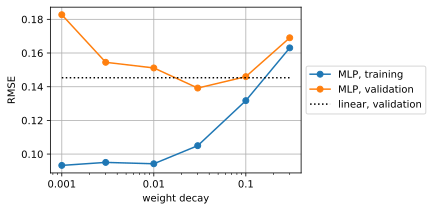

In [15]:
wds = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
mlp = {}
for wd in wds:
    print(f'weight decay {wd}: ', end='')
    mlp[wd] = k_fold(folds, lambda num_inputs: make_mlp(num_inputs, wd))
d2l.plot(wds, [[mlp[wd][0].mean() for wd in wds],
               [mlp[wd][1].mean() for wd in wds], [linear[1].mean()] * 6],
         'weight decay', 'RMSE', xscale='log', fmts=('C0-o', 'C1-o', 'k:'),
         legend=['MLP, training', 'MLP, validation', 'linear, validation'],
         legend_loc='outside', figsize=(4.5, 3))

<!-- d2l:prose id=kaggle-house-price-md-15 fw=all -->

Selecting the weight decay `best` with the lowest 5-fold mean validation RMSE, we can also inspect the paired per-fold difference `mlp[best][1] - linear[1]` where fold-sampling noise cancels out:

In [16]:
best = min(wds, key=lambda wd: mlp[wd][1].mean())
print(f'weight decay {best}: MLP minus linear, per fold',
      np.round(mlp[best][1] - linear[1], 3))

weight decay 0.03: MLP minus linear, per fold [-0.009  0.    -0.029  0.012 -0.006]


<!-- d2l:prose id=kaggle-house-price-md-16 fw=all -->

The cross-validation curve traces a textbook U-shape: weak weight decay (`wd = 0.001`) overfits the training folds (training RMSE $\sim 0.09$, validation RMSE $\sim 0.15$–$0.18$, worse than linear regression), intermediate weight decay (`wd = 0.03` or `0.1`) hits the sweet spot at validation RMSE $\sim 0.13$–$0.14$ (beating the linear baseline on most folds), and excessive decay (`wd = 0.3`) underfits.

## Submitting Predictions

With the winning weight decay `best` selected by 5-fold cross-validation, we retrain `HouseMLP` on all $1{,}460$ labeled houses (or ensemble the 5 fold models; see Exercise 5), add back the training mean log-price `data.offset`, exponentiate to dollar predictions, and save `submission.csv`:

In [17]:
data = KaggleHouse(raw_train, raw_test)
model = make_mlp(data.num_inputs, wd=best)
trainer = d2l.Trainer(max_epochs=100)
trainer.board.display = False
trainer.fit(model, data)
log_price = d2l.numpy(model(d2l.tensor(data.X_val))).reshape(-1) + data.offset
submission = pd.DataFrame({'Id': raw_test['Id'],
                           'SalePrice': np.exp(log_price)})
submission.to_csv('submission.csv', index=False)
submission.head()

     Id      SalePrice
0  1461  119006.625000
1  1462  154548.484375
2  1463  177151.687500
3  1464  201103.609375
4  1465  186113.750000

<!-- d2l:prose id=kaggle-house-price-md-17 fw=all -->

## Summary

Real-world tabular regression hinges on disciplined, leakage-free preprocessing: dropping arbitrary row identifiers, recasting numeric category codes to strings, standardizing numerical columns with training-split means and standard deviations before zero-imputing missing entries, one-hot encoding categoricals with an explicit missingness indicator, and centering log-transformed targets around the training mean. Evaluating all candidate models on the same $K = 5$ cross-validation folds—each refitting its own preprocessor on its four training folds—cancels fold-sampling noise when comparing models head to head. On Ames Housing, tuning $\ell_2$ weight decay moves a 22,000-parameter ReLU MLP from overfitting ($\sim 0.15$–$0.18$ log-RMSE) past the linear baseline ($\sim 0.15$) to $\sim 0.13$–$0.14$ log-RMSE, though gradient-boosted decision trees remain a strong competitor on heterogeneous tabular features (Exercise 3).

## Exercises

1. [code] **Mean imputation.** `preprocess` replaces every missing
   numerical value by the training-set mean of its column. Its call to
   `pd.get_dummies` with `dummy_na=True` also adds a missing-value
   indicator column for every categorical feature.
    1. Identify a numerical feature in this dataset whose missingness is not
       random with respect to the sale price.
    1. Explain what bias mean imputation alone would introduce for that
       feature, and in which direction it would shift the predictions for
       the affected houses. Then determine whether the indicator columns
       that `preprocess` already creates let a linear model remove this
       bias.
    1. Replace mean imputation by median imputation, and separately add a
       binary missingness indicator column for each imputed feature. Compare
       the cross-validated errors of the three variants.

    *Adapted from Kaggle Learn,
    [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning),
    Exercise 2.*

1. [code] **Scaling the features and the target.** Remove the
   standardization from `preprocess`. Because `fillna(0)` imputes the
   column mean only for standardized columns, fill missing numerical values
   with the training-set column means explicitly instead.
    1. Rerun the cross-validation of the linear model at the section's
       learning rate of $0.02$, and describe the training loss.
    1. Find, to within a factor of ten, the largest learning rate at which
       the unstandardized linear model trains without diverging. Compare
       its cross-validated error after $100$ epochs with that of the
       standardized pipeline, and explain both observations.
    1. Restore the standardization, but train on the log prices without
       subtracting their mean. Compare the cross-validated error after
       $100$ epochs with that of the centered targets, and explain the
       difference.
    1. With the section's pipeline, record the validation RMSE of the linear
       model and the mean of its residuals on the validation fold after
       every epoch. In the epochs where the RMSE jumps, what has moved?
       Every house has exactly 44 one-hot features equal to 1 (45 inputs
       equal to 1 if we count the bias). Explain why a step of SGD
       changes the mean prediction more than it changes any single weight,
       and check whether halving the learning rate removes the jumps.
1. [code] **Gradient-boosted trees.** On tabular data like this,
   ensembles of decision trees often predict better than neural networks
   [@Grinsztajn.Oyallon.Varoquaux.2022; @Shwartz-Ziv.Armon.2022]. Fit a
   gradient-boosted tree model (for example scikit-learn's
   `GradientBoostingRegressor`, or XGBoost or LightGBM if installed) to the
   centered log prices of the training rows of each fold in `folds`, and
   compute its validation RMSE on each fold. Compare the average with those
   of this section's models. Which properties of the data favor trees?
1. [code] **Target leakage.** A feature that is recorded only after, or
   because of, the event being predicted inflates validation scores without
   helping a deployed model.
    1. Identify at least one raw feature in this dataset that could
       plausibly be filled in only after the sale, and explain why
       cross-validation does not catch the problem.
    1. Verify the mechanism empirically: add a synthetic feature equal to
       the log sale price plus small Gaussian noise, rerun the
       cross-validation, and report the change in the validation RMSE.

    *Adapted from Kaggle Learn,
    [Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning),
    Exercise 7.*
1. [code] **Fold ensembling versus retraining.**
   that section retrains the selected MLP on all
   houses. Alternatively, the five models trained during cross-validation
   could each predict the test houses, with the preprocessing of their own
   round, and their log-price predictions could be averaged.
    1. Implement this fold ensemble and submit both its predictions and
       those of the retrained model. Compare the two leaderboard scores with
       each other and with the cross-validated RMSE.
    1. Each model of the ensemble was trained on four fifths of the houses.
       Why might the ensemble nevertheless predict better than the model
       retrained on all of them?
    1. Explain why the training error of the retrained model is not a
       substitute for the cross-validated estimate.
1. [code] **Target encoding.** ● *Target encoding* replaces each category
   of a categorical column by the mean log sale price of the training rows
   in that category, so that the feature occupies a single column instead
   of the one column per category that `preprocess` creates.
    1. Target-encode every categorical column with more than ten categories
       instead of one-hot encoding it, computing the category means from
       the training rows of each fold. Give a category that does not occur
       in those rows the overall mean, and standardize the encoded columns
       like the numerical features. Compare the cross-validated error with
       that of one-hot encoding.
    1. The encoding above computes each training row's value from a mean
       that includes that row's own label. Encode the training rows out of
       fold instead: split the training rows of each fold into five parts,
       and encode each part with category means computed from the other four
       parts. Compare the cross-validated error with that of the in-sample
       encoding, and explain how the size of a category affects the
       difference between the two encodings.

1. **Geometric averaging.** ● An ensemble of $K$ models that predict the log
   prices $z_1, \ldots, z_K$ of a house can average them before
   exponentiating, which amounts to a geometric mean in price space.
    1. Compare $\exp\bigl(\frac{1}{K}\sum_{k=1}^K z_k\bigr)$ with the
       price-space average $\frac{1}{K}\sum_{k=1}^K e^{z_k}$. Show which of
       the two never exceeds the other, and state when they coincide.
    1. Let $\log y$ be the true log price of the house. Show that the
       log-space average satisfies

       $$\Bigl(\log y - \frac{1}{K}\sum_{k=1}^K z_k\Bigr)^2 \leq \frac{1}{K}\sum_{k=1}^K \left(\log y - z_k\right)^2.$$

       Determine whether the logarithm of the price-space average satisfies
       the same bound for all predictions $z_1, \ldots, z_K$.

<!-- d2l:prose id=kaggle-house-price-md-18 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/107)